In [40]:
import numpy as np
import pandas as pd
import pandapipes as pp
import matplotlib.pyplot as plt

# Network setup

In [41]:
# ---------------------------------------------------------------------------
# Read topology and input data
# ---------------------------------------------------------------------------
pipes_file = "pipes.csv"
nodes_file = "nodes.csv"

pipe_data = pd.read_csv(pipes_file)
node_data = pd.read_csv(nodes_file)

# ---------------------------------------------------------------------------
# Create network
# ---------------------------------------------------------------------------
net = pp.create_empty_network(name="DHN_THV_3G_L_S_BASE")

# ---------------------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------------------
t_initial_C = 20        # °C
p_initial_bar = 10      # bar

# --------------------------------------------------------------------------
# Define fluid
# ---------------------------------------------------------------------------
fluid_props = dict(
    name = "water_80",
    fluid_type = "liquid",
    density = 971.8,
    viscosity = 0.000354,
    heat_capacity = 4195.0,
    thermal_conductivity = 0.67,
    temperature = 80 + 273.15
)

from pandapipes.properties.fluids import create_constant_fluid
fluid = create_constant_fluid(**fluid_props)
net.fluid = fluid

# --------------------------------------------------------------------------
# Define junctions
# ---------------------------------------------------------------------------
OFFSET_X = 50   # m — return circuit offset for visualisation

node_map = {}

for _, row in node_data.iterrows():
    name      = row["node_id"]
    node_type = row["node_type"]      # "source", "junction", "substation"
    x         = float(row["x_m"])
    y         = float(row["y_m"])

    # supply junction
    j_s = pp.create_junction(
        net,
        pn_bar=p_initial_bar,
        tfluid_k=t_initial_C + 273.15,
        name=f"{name}_s",
        geodata=(x, y)
    )

    # return junction
    j_r = pp.create_junction(
        net,
        pn_bar=p_initial_bar,
        tfluid_k=t_initial_C + 273.15,
        name=f"{name}_r",
        geodata=(x + OFFSET_X, y)
    )

    node_map[name] = {"supply": j_s, "return": j_r}

    # --- SOURCE — circulation pump ---
    if node_type == "source":
        p_flow_bar = float(row["p_pump_set_bar"])
        t_supply_k = float(row["T_supply_set_degC"]) + 273.15
        pp.create_circ_pump_const_pressure(
            net,
            return_junction=j_r,
            flow_junction=j_s,
            p_flow_bar=p_flow_bar,
            plift_bar=2.0,
            t_flow_k=t_supply_k,
            name="src"
        )

    # --- SUBSTATIONS — heat consumer ---
    if node_type == "substation":
        deltat_nom_k = float(row["delta_T_nom_K"])
        pp.create_heat_consumer(
            net,
            from_junction=j_s,
            to_junction=j_r,
            deltat_k=deltat_nom_k,
            qext_w=175_000,
            name=name
        )

# ---------------------------------------------------------------------------
# Define pipes
# ---------------------------------------------------------------------------
for _, row in pipe_data.iterrows():
    from_node = row["from_node"]
    to_node = row["to_node"]
    pid = row["pipe_id"]

    from_j_s = node_map[from_node]["supply"]
    to_j_s = node_map[to_node]["supply"]
    from_j_r = node_map[to_node]["return"]
    to_j_r = node_map[from_node]["return"]

    params = dict(
        length_km=float(row["length_m"]) / 1e3,
        inner_diameter_mm=float(row["d_inner_m"]) * 1e3,
        outer_diameter_mm=float(row["d_outer_m"]) * 1e3,
        k_mm=float(row["roughness_m"]) * 1e3,
        u_w_per_m2k=float(row["U_Wm2K"]),
        text_k=float(row["T_ground_degC"]) + 273.15
    )

    # supply pipe
    pp.create_pipe_from_parameters(
        net,
        from_junction=from_j_s,
        to_junction=to_j_s,
        name=f"{pid}_s",
        **params
    )
    # return pipe
    pp.create_pipe_from_parameters(
        net,
        from_junction=from_j_r,
        to_junction=to_j_r,
        name=f"{pid}_r",
        **params
    )

print(net)

This pandapipes network includes the following parameter tables:
   - junction (38 elements)
   - junction_geodata (38 elements)
   - pipe (38 elements)
   - heat_consumer (10 elements)
   - circ_pump_pressure (1 elements).
It contains the following fluid: 
Fluid water_80 (liquid) with properties:
   - density (Constant)
   - viscosity (Constant)
   - heat_capacity (Constant)
   - thermal_conductivity (Constant)
   - temperature (Constant)
and uses the following component models:
   - Junction
   - Pipe
   - Valve
   - Pump
   - Sink
   - Source
   - Compressor
   - FlowControlComponent
   - PressureControlComponent
   - MassStorage
   - HeatConsumer
   - HeatExchanger
   - CirculationPumpMass
   - CirculationPumpPressure
   - ExtGrid


In [42]:
# ---------------------------------------------------------------------------
# Steady-state simulation — peak load initialisation
# ---------------------------------------------------------------------------
pp.pipeflow(
    net,
    friction_model="colebrook",
    mode="bidirectional"
)

print("Simulation converged.")

Simulation converged.


# Snapshot time simulation

In [43]:
# ---------------------------------------------------------------------------
# Build boundary condition profiles for all heat consumers
# ---------------------------------------------------------------------------
demand_profile_file = "../../data/demand_profile.csv"
demand_profile_data = pd.read_csv(demand_profile_file)

qext_w_ts   = demand_profile_data["Q_W"].values
NUM_SIM_STEPS = len(qext_w_ts)
deltat_k_ts = np.full(len(qext_w_ts), deltat_nom_k)

qext_profile = pd.DataFrame(
    data=np.tile(qext_w_ts  .reshape(-1, 1), (1, len(net.heat_consumer.index.values))),
    columns=net.heat_consumer.name.values
)

deltat_profile = pd.DataFrame(
    data=np.tile(deltat_k_ts.reshape(-1, 1), (1, len(net.heat_consumer.index.values))),
    columns=net.heat_consumer.name.values
)

# --- Handle zero-demand timesteps ---
# When Q=0, set both qext and deltat to a numerically safe minimum
# to avoid mdot=0 which causes solver divergence
qext_min  = 1e-6
deltat_min = 1e-6

mask = qext_profile < qext_min
qext_profile[mask]  = qext_min
deltat_profile[mask] = deltat_min

# --- DFData ---
from pandapower.timeseries import DFData

qext_profile_data  = DFData(qext_profile)
deltat_profile_data = DFData(deltat_profile)

print("--- Data setup is defined. ---")

# --- Controller ---
from pandapower.control.controller.const_control import ConstControl

for i, hc_idx in enumerate(net.heat_consumer.index):

    ConstControl(
        net,
        element="heat_consumer",
        variable="qext_w",
        element_index=hc_idx,
        profile_name=net.heat_consumer.name.values[i],
        data_source=qext_profile_data
    )

    ConstControl(
        net,
        element="heat_consumer",
        variable="deltat_k",
        element_index=hc_idx,
        profile_name=net.heat_consumer.name.values[i],
        data_source=deltat_profile_data
    )

# --- Run time series ---
from pandapipes.timeseries import run_time_series
from pandapower.timeseries import OutputWriter

log_variables = [
    ('res_junction', 't_k'),
    ('res_junction', 'p_bar'),
    ('res_pipe', 'mdot_from_kg_per_s'),
    ('res_heat_consumer', 't_from_k'),
    ('res_heat_consumer', 't_to_k'),
    ('res_heat_consumer', 'mdot_from_kg_per_s'),
    ('res_circ_pump_pressure', 'mdot_from_kg_per_s'),
    ('res_circ_pump_pressure', 'qext_w')
]

ow = OutputWriter(net, range(NUM_SIM_STEPS), output_path=None, log_variables=log_variables)

import time
# --- Simulation time ---
start_time = time.perf_counter()

run_time_series.run_timeseries(net, range(NUM_SIM_STEPS), mode="bidirectional", verbose=False)
end_time = time.perf_counter()
sim_time_total = end_time - start_time

print(f"Average simulation time: {sim_time_total:.2f} s")
print("--- Timeseries completed. ---")

--- Data setup is defined. ---
Average simulation time: 16.55 s
--- Timeseries completed. ---


In [44]:
# ---------------------------------------------------------------------------
# Post-processing — extract and plot time series results
# ---------------------------------------------------------------------------
dt_min = 10
time_h = np.arange(NUM_SIM_STEPS) * dt_min / 60

results = ow.output

In [71]:
t_node = results["res_junction.t_k"] - 273.15
t_node.columns = net.junction.name

<Axes: >

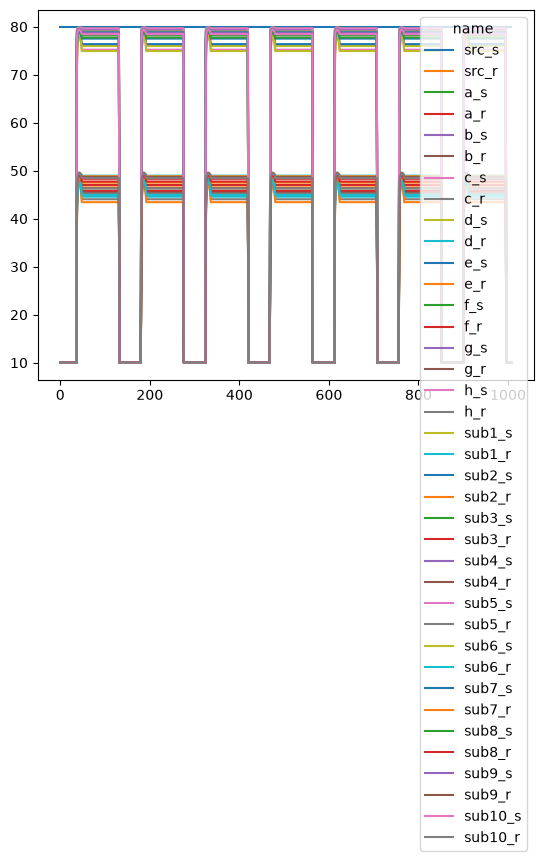

In [73]:
t_node.plot()

In [46]:
mdot_pipe = results["res_pipe.mdot_from_kg_per_s"]
mdot_pipe.columns = net.pipe.name

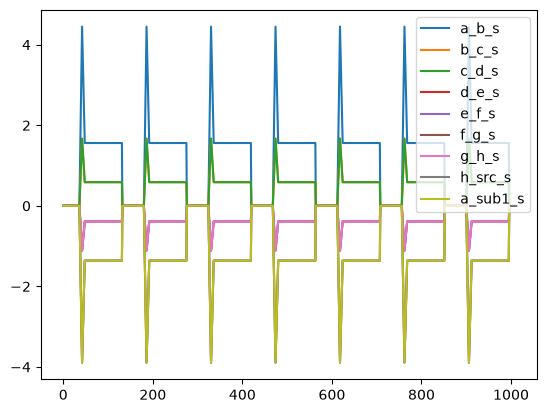

In [67]:
mdot_pipe["a_b_s"].plot(label=net.pipe.name[2])
mdot_pipe["b_c_s"].plot(label=net.pipe.name[4])
mdot_pipe["c_d_s"].plot(label=net.pipe.name[6])
mdot_pipe["d_e_s"].plot(label=net.pipe.name[8])
mdot_pipe["e_f_s"].plot(label=net.pipe.name[10])
mdot_pipe["f_g_s"].plot(label=net.pipe.name[12])
mdot_pipe["e_f_s"].plot(label=net.pipe.name[14])
mdot_pipe["f_g_s"].plot(label=net.pipe.name[16])
mdot_pipe["g_h_s"].plot(label=net.pipe.name[18])
plt.legend()

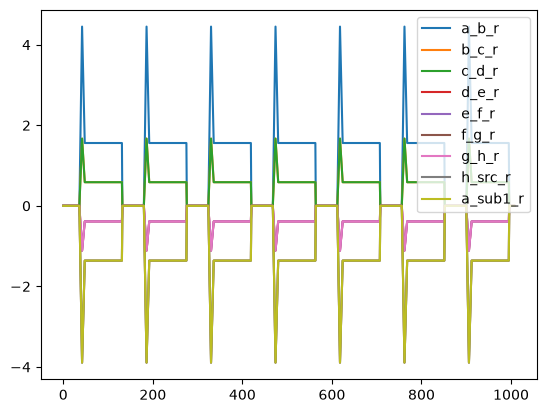

In [70]:
mdot_pipe["a_b_r"].plot(label=net.pipe.name[2+1])
mdot_pipe["b_c_r"].plot(label=net.pipe.name[4+1])
mdot_pipe["c_d_r"].plot(label=net.pipe.name[6+1])
mdot_pipe["d_e_r"].plot(label=net.pipe.name[8+1])
mdot_pipe["e_f_r"].plot(label=net.pipe.name[10+1])
mdot_pipe["f_g_r"].plot(label=net.pipe.name[12+1])
mdot_pipe["e_f_r"].plot(label=net.pipe.name[14+1])
mdot_pipe["f_g_r"].plot(label=net.pipe.name[16+1])
mdot_pipe["g_h_r"].plot(label=net.pipe.name[18+1])
plt.legend()